## Effectiveness: what drives swings and misses?

#### Question
Which features of a pitch are associated with a whiff when the batter swings, and do the Blue Jays' pitchers differ from what other teams' pitchers get in the same situations?

#### Approach
- **Outcome:** whiff per swing (1 = swing and miss, 0 = contact). Bunt attempts are excluded.
- **Explanatory, not predictive:** we want to understand what is behind whiffs, so the focus is on the coefficients, their uncertainty, and whether results hold up under different model choices.
- **Start simple:** logistic regression with pitcher-clustered standard errors, then a mixed model as a check.

#### Libraries

In [1]:
# Imports

# Data manipulation
import numpy as np
import pandas as pd 
# Data visualization
import matplotlib.pyplot as plt 
import seaborn as sns
# Logistic regression
import statsmodels.api as sm
import statsmodels.formula.api as smf
# Binomial Bayes - Random Int Model
from statsmodels.genmod.bayes_mixed_glm import BinomialBayesMixedGLM
# Comparison metrics
from sklearn.metrics import roc_auc_score, log_loss
# Tests
from scipy import stats

## Data

In [2]:
# Master file built in the Setup notebook
df = pd.read_csv('FullData_V2.csv', dtype={'base_state': str})

In [3]:
keep_vars = [
    # Identifiers
    'pitcher', 'player_name', 'pitching_team', 'game_pk', 'game_date', 'game_type',
    'outing_id', 'batter', 'home_team', 'away_team', 'inning_topbot',

    # Outcome Source
    'description', 'is_bunt', 'swing', 'whiff',

    # predictors
    'is_jays', 'release_speed', 'pitch_type', 'balls', 'strikes', 'stand', 'p_throws',
    'zone', 'plate_x', 'plate_z', 'sz_top', 'sz_bot',
    'outs_when_up', 'base_state_label', 'outing_pitch_count', 'pitcher_role'
]

# Safety Check
missing_cols = [c for c in keep_vars if c not in df.columns]
print("Not in df: ", missing_cols)
assert not missing_cols, f"Not in FullData_V2: {missing_cols}"

# New working df (will be further altered)
wdf = df[keep_vars].copy()
print(wdf.shape)

Not in df:  []
(14096, 31)


<p> Now we want our dependent variable (wiff) to measure effectiveness. The wiff, swing and bunt flags were created in Setup, so here we confirm they reproduce the Setup numbers. Wiff is only valid where a swing occurs, so we are gonna use a fuller data set to create/transform variables, and then copy swings only when needed.

In [4]:
print(wdf['is_bunt'].sum(), "bunt rows")

# Working feature dataset (bunt attempts removed)
non_bunt_pitches = wdf[~wdf['is_bunt']].copy()

# Wiff is only defined when a swing occurs - model dataset
swings_only = non_bunt_pitches[non_bunt_pitches['swing']].copy()
print(len(non_bunt_pitches), len(swings_only), swings_only['whiff'].mean())

# Reproduce the Setup numbers before modelling anything
assert len(wdf) == 14096 and len(swings_only) == 6842, 'Counts differ from Setup'
assert round(swings_only['whiff'].mean(), 4) == 0.2789, 'Whiff rate differs from Setup'
# Location is needed on every swing
assert swings_only[['plate_x', 'plate_z', 'sz_top', 'sz_bot']].notna().all().all(), 'Missing location on a swing'

33 bunt rows
14063 6842 0.278865828705057


<p> After some checks we want to have better predictors in the model. Speed alone doesn't account for pitch type. Speed and pitch type together ignore the fact that some pitchers might differ then their own normals.

In [5]:
# Merge a rare SV (slurve) pitch into curveball
non_bunt_pitches['pitch_type'] = non_bunt_pitches['pitch_type'].replace({'SV': 'CU'})

# Same-handed matchup (1 = batter and pitcher hands match)
non_bunt_pitches['same_hand'] = (non_bunt_pitches['stand'] == non_bunt_pitches['p_throws']).astype(int)

# Pitch count in units of 10 pitches (coefficient = effect per 10 pitches)
non_bunt_pitches['pc10'] = non_bunt_pitches['outing_pitch_count'] / 10

# Base state as a categorical label
non_bunt_pitches['base_state_label'] = non_bunt_pitches['base_state_label'].astype(str)

# Average release speed of pitch type across ALL pitchers
non_bunt_pitches['pt_mean'] = non_bunt_pitches.groupby('pitch_type')['release_speed'].transform('mean')
# The within pitcher release speed average (e.g Gausman's fastball avg)
non_bunt_pitches['pp_mean'] = non_bunt_pitches.groupby(['pitcher', 'pitch_type'])['release_speed'].transform('mean')
# The number of pitches that make up the pp_mean (reliability metric for some less common pitchers)
non_bunt_pitches['pp_n'] = non_bunt_pitches.groupby(['pitcher', 'pitch_type'])['release_speed'].transform('size')

# The difference from the pitcher's individual average
non_bunt_pitches['velo_within']  = non_bunt_pitches['release_speed'] - non_bunt_pitches['pp_mean']
# The difference between the pitcher's average and the postseason average
non_bunt_pitches['velo_between'] = non_bunt_pitches['pp_mean'] - non_bunt_pitches['pt_mean']

# Horizontal location in feet from the middle of the plate, mirrored by batter side so + = away from the batter
non_bunt_pitches['x_away'] = np.where(non_bunt_pitches['stand'] == 'R',
                                      non_bunt_pitches['plate_x'], -non_bunt_pitches['plate_x'])
# Height relative to this batter's zone: 0 = middle of the zone, -1 = bottom edge, +1 = top edge
non_bunt_pitches['z_rel'] = ((non_bunt_pitches['plate_z'] - (non_bunt_pitches['sz_top'] + non_bunt_pitches['sz_bot']) / 2)
                             / ((non_bunt_pitches['sz_top'] - non_bunt_pitches['sz_bot']) / 2))
# Batting team (the away team bats in the top half)
non_bunt_pitches['bat_team'] = np.where(non_bunt_pitches['inning_topbot'] == 'Top',
                                        non_bunt_pitches['away_team'], non_bunt_pitches['home_team'])

# Swing only with new vars
swings_only = non_bunt_pitches[non_bunt_pitches['swing']].copy()

In [6]:
# Round the means - too many trailing decimals
cols_to_round = ['pt_mean', 'pp_mean', 'velo_within', 'velo_between']
non_bunt_pitches[cols_to_round] = non_bunt_pitches[cols_to_round].round(4)

swings_only = non_bunt_pitches[non_bunt_pitches['swing']].copy()

In [7]:
model_cols = ['whiff', 'pitcher', 'player_name', 'outing_id', 'batter', 'bat_team', 'is_jays', 'pc10',
              'velo_within', 'velo_between', 'pitch_type', 'balls', 'strikes', 'same_hand', 'zone',
              'x_away', 'z_rel', 'pitcher_role', 'outs_when_up', 'base_state_label']
model_df = swings_only[model_cols].copy()
print(model_df.shape, model_df.isna().sum().sum())

(6842, 20) 0


In [8]:
def base_group(s):
    if s == 'Empty':
        return 'Empty'
    if s == '1st only':
        return 'First only'
    return 'Scoring position'

model_df['base_group'] = swings_only['base_state_label'].map(base_group)
print(model_df['base_group'].value_counts())

base_group
Empty               3946
Scoring position    1627
First only          1269
Name: count, dtype: int64


The model data is 6,842 swings from 143 pitchers and 475 outings, with a whiff rate of 27.9%, reproducing the Setup numbers. We merged the rare slurve into curveballs, split each pitch's speed into the pitcher's own norm (`velo_within`) and the pitcher's usual speed against the league (`velo_between`), and grouped base states into three (Empty, First only, Scoring position), a choice made after seeing the whiff rates. We also built two location measures (`x_away`, `z_rel`) and the batting team for later checks.

## Checks before modelling

Before fitting anything we check what the model depends on: how much data each pitcher contributes, how the two speed measures behave, how pitch count and role overlap, and where each pitch type is thrown and who it was thrown against.

Quick Checks

In [9]:
# Swings before the slurve merge, so the rare pitch type is still visible
swings_pre = wdf[(~wdf['is_bunt']) & wdf['swing']]

# swings per pitcher, all teams
print(swings_pre.groupby('pitcher').size().describe())

# swings per Jays pitcher
jays = swings_pre[swings_pre['pitching_team'] == 'TOR']
print(jays.groupby('player_name').size().sort_values())

# rare pitch types
print(swings_pre.groupby('pitch_type')['whiff'].agg(['size', 'mean']))

# reliability of each pitcher's own speed average, and are Jays pitchers faster or slower than the league
print(swings_only['pp_n'].describe())
print(swings_only.groupby('is_jays')['velo_between'].mean())

count    143.000000
mean      47.846154
std       47.025661
min        1.000000
25%       16.500000
50%       33.000000
75%       60.000000
max      259.000000
dtype: float64
player_name
Bruihl, Justin             5
Rodríguez, Yariel         15
Nance, Tommy              17
Little, Brendon           36
Fisher, Braydon           56
Bassitt, Chris            58
Lauer, Eric               62
Fluharty, Mason           73
Domínguez, Seranthony     78
Hoffman, Jeff             96
Scherzer, Max            117
Varland, Louis           117
Bieber, Shane            149
Yesavage, Trey           200
Gausman, Kevin           217
dtype: int64
            size      mean
pitch_type                
CH           541  0.365989
CU           436  0.350917
FC           417  0.223022
FF          2347  0.224542
FS           505  0.417822
KC           158  0.417722
SI           890  0.153933
SL          1182  0.333333
ST           337  0.353116
SV            29  0.344828
count    6842.000000
mean       60.976907

Role Checks

In [10]:
# 1 = role is fixed per pitcher
print(swings_only.groupby('pitcher')['pitcher_role'].nunique().value_counts())
print(pd.crosstab(swings_only['is_jays'], swings_only['pitcher_role'], normalize='index'))
print(swings_only.groupby('pitcher_role')['whiff'].agg(['size', 'mean']))
print(swings_only.groupby('pitcher_role')['outing_pitch_count'].describe())

pitcher_role
1    124
2     19
Name: count, dtype: int64
pitcher_role  reliever   starter
is_jays                         
0             0.509556  0.490444
1             0.482253  0.517747
              size      mean
pitcher_role                
reliever      3451  0.252680
starter       3391  0.305515
               count       mean        std  min   25%   50%   75%    max
pitcher_role                                                            
reliever      3451.0  14.587366  12.676081  1.0   6.0  11.0  19.0   84.0
starter       3391.0  41.616337  26.369923  1.0  19.0  39.0  62.0  116.0


Base State and Zone

In [11]:
# Whiff rate by base state (evidence behind the 3-level grouping) and by zone (thin cells)
for c in ['base_state_label', 'zone']:
    print(swings_only.groupby(c)['whiff'].agg(['size', 'mean']))

                  size      mean
base_state_label                
1st & 2nd          516  0.286822
1st & 3rd          187  0.213904
1st only          1269  0.256107
2nd & 3rd          113  0.230088
2nd only           470  0.257447
3rd only           118  0.254237
Empty             3946  0.292955
Loaded             223  0.278027
      size      mean
zone                
1      373  0.222520
2      586  0.215017
3      344  0.252907
4      562  0.119217
5      765  0.132026
6      587  0.183986
7      392  0.260204
8      633  0.195893
9      445  0.283146
11     379  0.306069
12     367  0.329700
13     606  0.462046
14     803  0.581569


is_jays     0    1
pc_bin            
1-15     2359  588
16-30    1243  268
31-45     691  135
46-60     497  131
61-75     382  105
76+       374   69


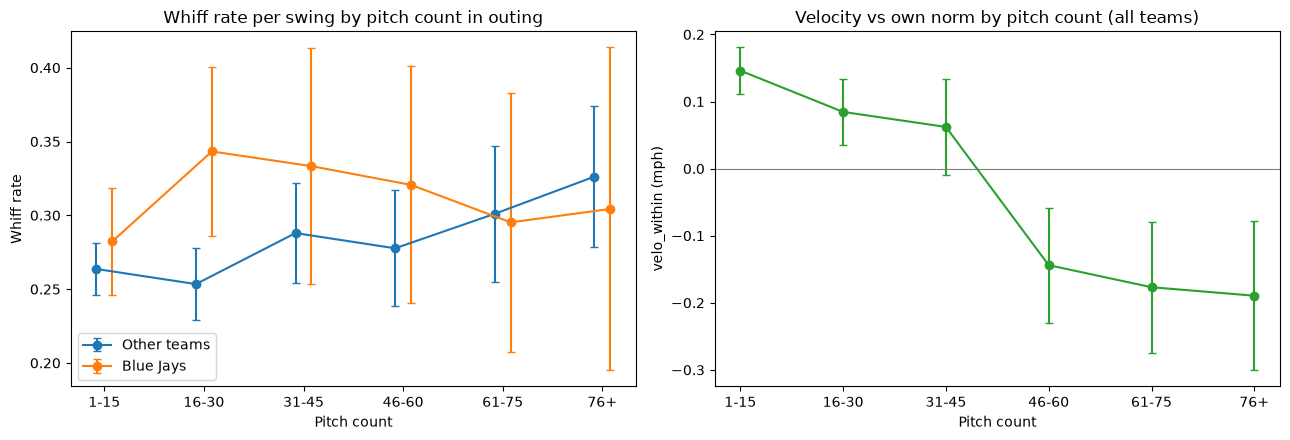

In [12]:
edges  = [0, 15, 30, 45, 60, 75, 200]
labels = ['1-15', '16-30', '31-45', '46-60', '61-75', '76+']
swings_only['pc_bin'] = pd.cut(swings_only['outing_pitch_count'], edges, labels=labels)

# Swings per bin: check for thin bins
print(swings_only.groupby(['is_jays', 'pc_bin'], observed=True).size().unstack(0))

def binned(frame, col):
    g = frame.groupby('pc_bin', observed=True)[col].agg(['mean', 'count', 'std']).reindex(labels)
    g['se'] = g['std'] / np.sqrt(g['count'])
    return g

x = np.arange(len(labels))
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

# 1. Whiff rate vs pitch count, Jays vs others
for flag, name, off in [(0, 'Other teams', -0.08), (1, 'Blue Jays', 0.08)]:
    g = binned(swings_only[swings_only['is_jays'] == flag], 'whiff')
    ax[0].errorbar(x + off, g['mean'], yerr=1.96 * g['se'], marker='o', capsize=3, label=name)
ax[0].set_xticks(x); ax[0].set_xticklabels(labels)
ax[0].set(title='Whiff rate per swing by pitch count in outing', xlabel='Pitch count', ylabel='Whiff rate')
ax[0].legend()

# 2. Velocity vs own norm by pitch count
g = binned(swings_only, 'velo_within')
ax[1].errorbar(x, g['mean'], yerr=1.96 * g['se'], marker='o', capsize=3, color='tab:green')
ax[1].axhline(0, color='grey', lw=0.8)
ax[1].set_xticks(x); ax[1].set_xticklabels(labels)
ax[1].set(title='Velocity vs own norm by pitch count (all teams)', xlabel='Pitch count', ylabel='velo_within (mph)')

plt.tight_layout()
plt.show()

,swings,height,height_sd,away,outside_zone,whiff
pitch_type,,,,,,
KC,158,-0.98,0.62,0.06,0.47,0.42
CU,465,-0.80,0.81,0.06,0.41,0.35
FS,505,-0.79,0.74,0.13,0.46,0.42
CH,541,-0.62,0.67,0.35,0.42,0.37
SL,1182,-0.53,0.76,0.15,0.36,0.33
ST,337,-0.51,0.73,0.28,0.42,0.35
SI,890,0.02,0.63,-0.17,0.22,0.15
FC,417,0.05,0.72,0.00,0.28,0.22
FF,2347,0.40,0.64,-0.01,0.24,0.22


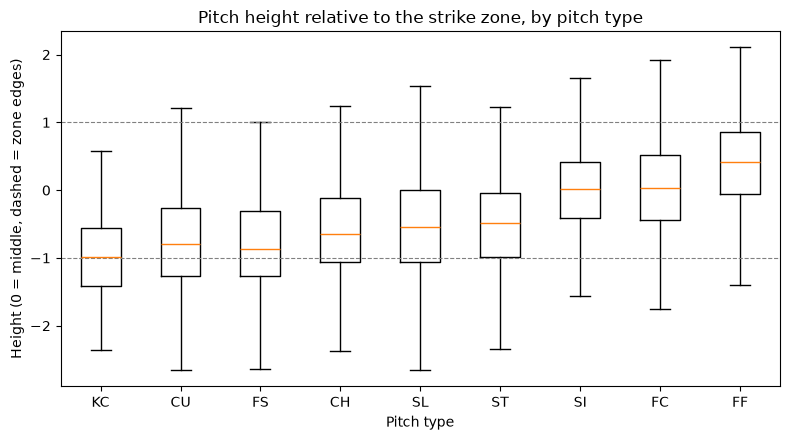

In [13]:
# Where each pitch type is thrown: height relative to the zone (0 = middle, -1 = bottom edge) and its spread,
# side (+ = away from the batter), share of swings outside the strike zone, and whiff per swing
loc = swings_only.groupby('pitch_type').agg(
    swings=('whiff', 'size'),
    height=('z_rel', 'mean'),
    height_sd=('z_rel', 'std'),
    away=('x_away', 'mean'),
    outside_zone=('zone', lambda z: (z >= 11).mean()),
    whiff=('whiff', 'mean')).round(2).sort_values('height')
display(loc)

# Height of each pitch type relative to the strike zone
order = loc.index.tolist()
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.boxplot([swings_only.loc[swings_only['pitch_type'] == p, 'z_rel'] for p in order], showfliers=False)
ax.set_xticklabels(order)
ax.axhline(-1, color='grey', lw=0.8, ls='--')
ax.axhline(1, color='grey', lw=0.8, ls='--')
ax.set(title='Pitch height relative to the strike zone, by pitch type', xlabel='Pitch type',
       ylabel='Height (0 = middle, dashed = zone edges)')
plt.tight_layout()
plt.show()

In [14]:
# Whiff per swing by batting team, and how many of those swings came against Blue Jays pitchers
bt = swings_only.groupby('bat_team').agg(
    swings=('whiff', 'size'),
    whiff=('whiff', 'mean'),
    swings_vs_jays=('is_jays', 'sum')).round(3).sort_values('whiff')
display(bt)

,swings,whiff,swings_vs_jays
bat_team,,,
SD,201,0.219,0
TOR,1401,0.226,0
LAD,1264,0.277,546
CLE,197,0.279,0
MIL,568,0.282,0
CHC,562,0.290,0
DET,640,0.291,0
NYY,486,0.298,276
SEA,883,0.310,474


#### Summary
Pitch types are thrown to different parts of the zone (knuckle-curves near the bottom edge, four-seam fastballs above the middle), so pitch-type effects could partly be location effects, which the model must separate. Blue Jays pitchers faced only three opponents (LAD, SEA, NYY), whose whiff rates differ, so the batting team is a possible confounder. Starters and relievers differ a lot in outing length (median about 39 vs 11 pitches), and velocity drifts down only slightly as an outing goes on (about 0.3 mph), so pitch count and velocity are separated in the model. Most pitchers have few swings, which is why we use pitcher-clustered errors and a mixed model.

## M0: plain logistic regression (standard errors clustered by pitcher)

<p> Use a comparison logistic regression without random effects to compare the later model to. We fit it in three steps, each adding one thing, and report all three so the reader can see which results depend on the controls:
1. **Zones only:** the original model. Pitch location enters only through the 13 strike-zone cells.
2. **Plus location:** the exact side and height of the pitch (as a curve), because pitch types are thrown to different places (see the checks above).
3. **Plus batting team:** the Blue Jays faced only three opponents, so the opponent is a possible confounder.

Step 3 is the model we report. The Bonferroni correction is applied across the 15 displayed coefficients (0.05 / 15 = 0.0033) and shown next to the uncorrected p-values.

Three model formulas: the original, then the same model with the exact pitch location added, then with the batting team added as well.

In [15]:
# Situation controls only, then the full M0 (Step 1)
f_base = ('whiff ~ C(pitch_type, Treatment("FF")) + C(balls) + C(strikes) + same_hand '
          '+ C(zone) + C(pitcher_role) + C(outs_when_up) + C(base_group, Treatment("Empty"))')
f_m0 = f_base + ' + pc10 * is_jays + velo_within + velo_between'

# Step 2: exact side and height as a curve (squares and a cross term), on top of the zone dummies
f_m0_loc = f_m0 + ' + x_away + z_rel + I(x_away**2) + I(z_rel**2) + x_away:z_rel'

# Step 3: batting team added
f_m0_team = f_m0_loc + ' + C(bat_team)'

Fit Step 1 (zones only) with standard errors clustered by pitcher, and print the full regression output: every coefficient on the log-odds scale.

In [16]:
res0 = smf.logit(f_m0, data=model_df).fit(
    cov_type='cluster', cov_kwds={'groups': model_df['pitcher']}, disp=0)
print(res0.summary())

                           Logit Regression Results                           
Dep. Variable:                  whiff   No. Observations:                 6842
Model:                          Logit   Df Residuals:                     6805
Method:                           MLE   Df Model:                           36
Date:                Sun, 22 Nov 2026   Pseudo R-squ.:                  0.1052
Time:                        02:47:40   Log-Likelihood:                -3623.6
converged:                       True   LL-Null:                       -4049.6
Covariance Type:              cluster   LLR p-value:                1.445e-155
                                                            coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------------------------------------
Intercept                                                -1.1804      0.184     -6.430      0.000      -1.540      -0.821
C(

The same Step 1 fit as odds ratios with 95% intervals and p-values for every coefficient, including the zone, count, outs, role and handedness terms.

In [17]:
ci = res0.conf_int()
tab0 = pd.DataFrame({'OR': np.exp(res0.params), 'lo': np.exp(ci[0]),
                     'hi': np.exp(ci[1]), 'p': res0.pvalues})
tab0['Significant?'] = np.where(tab0['p'] < 0.05, 'Yes', 'No')

tab0.index = (tab0.index.str.replace('C(pitch_type, Treatment("FF"))[T.', 'vs FF: ', regex=False)
                        .str.replace('C(base_group, Treatment("Empty"))[T.', 'base: ', regex=False)
                        .str.replace(']', '', regex=False))

# Every coefficient, nothing hidden
print(tab0.round(3))

                              OR     lo     hi      p Significant?
Intercept                  0.307  0.214  0.440  0.000          Yes
vs FF: CH                  1.484  1.080  2.040  0.015          Yes
vs FF: CU                  1.330  1.005  1.761  0.046          Yes
vs FF: FC                  0.855  0.611  1.197  0.362           No
vs FF: FS                  1.911  1.317  2.773  0.001          Yes
vs FF: KC                  1.659  1.061  2.595  0.027          Yes
vs FF: SI                  0.608  0.496  0.745  0.000          Yes
vs FF: SL                  1.296  1.060  1.585  0.012          Yes
vs FF: ST                  1.405  1.104  1.788  0.006          Yes
C(balls)[T.1               1.141  1.002  1.300  0.047          Yes
C(balls)[T.2               1.146  0.990  1.327  0.067           No
C(balls)[T.3               1.086  0.850  1.389  0.508           No
C(strikes)[T.1             0.843  0.733  0.970  0.017          Yes
C(strikes)[T.2             0.577  0.480  0.694  0.000         

The 15 coefficients we report (pitch type, base state, pitch count, Jays, velocity), with Bonferroni-adjusted p-values next to the raw ones. The other terms are controls and stay in the full table above.

In [18]:
# Wider display so the table does not wrap
pd.set_option('display.width', 200)

# Controls left out of the reported table (they stay in the full output above)
hide = ('Intercept', 'C(zone)', 'C(balls)', 'C(strikes)', 'C(outs_when_up)',
        'C(pitcher_role)', 'same_hand')
rows = [i for i in tab0.index if not i.startswith(hide)]

# Bonferroni family = the displayed coefficients; the assert stops the family from changing silently
m = len(rows)
assert m == 15, f'Expected 15 tests, got {m}'
main0 = tab0.loc[rows].copy()
main0['p_bonf'] = (main0['p'] * m).clip(upper=1)
main0['Survives Bonferroni?'] = np.where(main0['p'] < 0.05 / m, 'Yes', 'No')
print(main0.round(3))

                           OR     lo     hi      p Significant?  p_bonf Survives Bonferroni?
vs FF: CH               1.484  1.080  2.040  0.015          Yes   0.223                   No
vs FF: CU               1.330  1.005  1.761  0.046          Yes   0.697                   No
vs FF: FC               0.855  0.611  1.197  0.362           No   1.000                   No
vs FF: FS               1.911  1.317  2.773  0.001          Yes   0.010                  Yes
vs FF: KC               1.659  1.061  2.595  0.027          Yes   0.398                   No
vs FF: SI               0.608  0.496  0.745  0.000          Yes   0.000                  Yes
vs FF: SL               1.296  1.060  1.585  0.012          Yes   0.173                   No
vs FF: ST               1.405  1.104  1.788  0.006          Yes   0.085                   No
base: First only        0.825  0.714  0.954  0.009          Yes   0.139                   No
base: Scoring position  0.795  0.694  0.911  0.001          Yes   0.01

Fit Steps 2 and 3 the same way, printing the full output for each. The only differences from Step 1 are the added terms.

In [19]:
# Steps 2 and 3, same pitcher-clustered standard errors
res_loc = smf.logit(f_m0_loc, data=model_df).fit(
    cov_type='cluster', cov_kwds={'groups': model_df['pitcher']}, disp=0)
print(res_loc.summary())

res_team = smf.logit(f_m0_team, data=model_df).fit(
    cov_type='cluster', cov_kwds={'groups': model_df['pitcher']}, disp=0)
print(res_team.summary())

steps = {'Step 1: zones only': res0, 'Step 2: + location': res_loc, 'Step 3: + batting team': res_team}

                           Logit Regression Results                           
Dep. Variable:                  whiff   No. Observations:                 6842
Model:                          Logit   Df Residuals:                     6800
Method:                           MLE   Df Model:                           41
Date:                Sun, 22 Nov 2026   Pseudo R-squ.:                  0.1544
Time:                        02:47:41   Log-Likelihood:                -3424.3
converged:                       True   LL-Null:                       -4049.6
Covariance Type:              cluster   LLR p-value:                1.640e-235
                                                            coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------------------------------------
Intercept                                                -1.8464      0.188     -9.833      0.000      -2.214      -1.478
C(

Compare the three steps on number of parameters, log-likelihood, AIC and BIC, then test each step against the one before it with a likelihood-ratio test. The test treats swings as independent, so with pitcher clustering it is approximate.

In [20]:
# Whiffs per parameter shows how thin the model is getting
fit = pd.DataFrame({
    'params': [r.df_model + 1 for r in steps.values()],
    'loglik': [r.llf for r in steps.values()],
    'AIC': [r.aic for r in steps.values()],
    'BIC': [r.bic for r in steps.values()]}, index=list(steps))
fit['whiffs_per_param'] = model_df['whiff'].sum() / fit['params']
print(fit.round(1))

# Likelihood-ratio test between neighbouring steps
step_names = list(steps)
for a, b in zip(step_names[:-1], step_names[1:]):
    chi2 = 2 * (steps[b].llf - steps[a].llf)
    df_diff = steps[b].df_model - steps[a].df_model
    print(f'{a} -> {b}: chi2 = {chi2:.1f} on {df_diff:.0f} df, p = {stats.chi2.sf(chi2, df_diff):.3g}')

                        params  loglik     AIC     BIC  whiffs_per_param
Step 1: zones only        37.0 -3623.6  7321.3  7574.0              51.6
Step 2: + location        42.0 -3424.3  6932.6  7219.4              45.4
Step 3: + batting team    53.0 -3408.8  6923.6  7285.7              36.0
Step 1: zones only -> Step 2: + location: chi2 = 398.7 on 5 df, p = 5.56e-84
Step 2: + location -> Step 3: + batting team: chi2 = 30.9 on 11 df, p = 0.00113


Odds ratios and p-values for the 15 reported coefficients side by side across the three steps, then which ones pass Bonferroni at each step, then the full interval for the Jays terms in Step 3. The full tables for Steps 2 and 3 are the summaries printed above.

In [21]:
# Same odds-ratio table builder as above, applied to every step
def or_table(res):
    ci = res.conf_int()
    t = pd.DataFrame({'OR': np.exp(res.params), 'lo': np.exp(ci[0]),
                      'hi': np.exp(ci[1]), 'p': res.pvalues})
    t.index = (t.index.str.replace('C(pitch_type, Treatment("FF"))[T.', 'vs FF: ', regex=False)
                      .str.replace('C(base_group, Treatment("Empty"))[T.', 'base: ', regex=False)
                      .str.replace(']', '', regex=False))
    return t

tabs = {n: or_table(r) for n, r in steps.items()}

# The 15 reported coefficients side by side
stab = pd.concat({n: t.loc[rows, ['OR', 'p']] for n, t in tabs.items()}, axis=1)
print(stab.round(3))

# Which coefficients survive Bonferroni at each step
for n, t in tabs.items():
    print(n, '->', [r for r in rows if t.loc[r, 'p'] < 0.05 / m])

# Full interval for the Jays terms in the reported model
print(tabs['Step 3: + batting team'].loc[['is_jays', 'pc10:is_jays'], ['OR', 'lo', 'hi', 'p']].round(3))

                       Step 1: zones only        Step 2: + location        Step 3: + batting team       
                                       OR      p                 OR      p                     OR      p
vs FF: CH                           1.484  0.015              1.388  0.029                  1.342  0.055
vs FF: CU                           1.330  0.046              1.094  0.558                  1.094  0.549
vs FF: FC                           0.855  0.362              0.873  0.445                  0.872  0.435
vs FF: FS                           1.911  0.001              1.639  0.007                  1.685  0.004
vs FF: KC                           1.659  0.027              1.319  0.241                  1.297  0.277
vs FF: SI                           0.608  0.000              0.693  0.001                  0.702  0.002
vs FF: SL                           1.296  0.012              1.149  0.192                  1.161  0.172
vs FF: ST                           1.405  0.006       

Odds-ratio plot for Step 3: the lines are 95% intervals, a filled dot means the coefficient passes the Bonferroni correction, and a hollow dot means it does not.

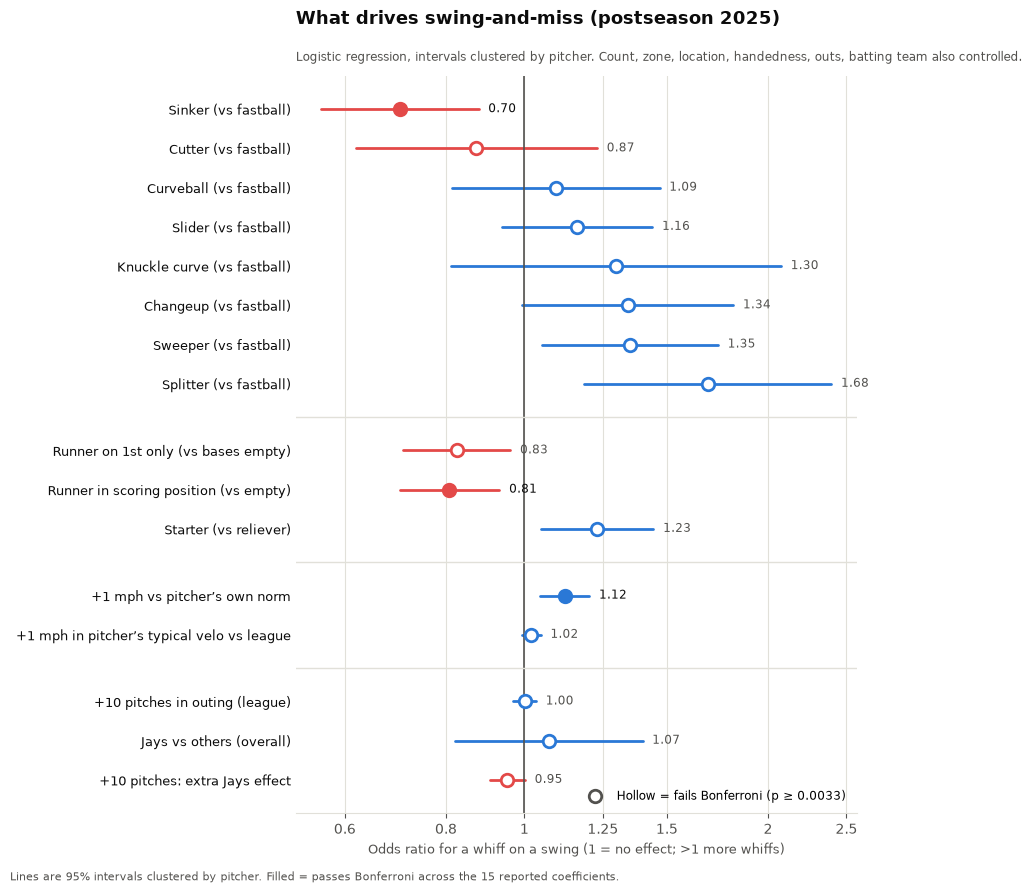

In [22]:
from matplotlib.lines import Line2D

BLUE, RED = '#2a78d6', '#e34948'
INK, MUTED, GRID = '#0b0b0b', '#52514e', '#e1e0d9'
PT = {'FF':'Fastball','SI':'Sinker','FC':'Cutter','SL':'Slider','ST':'Sweeper',
      'CU':'Curveball','KC':'Knuckle curve','CH':'Changeup','FS':'Splitter'}

def clean_axes(ax):
    for s in ['top','right','left']: ax.spines[s].set_visible(False)
    ax.spines['bottom'].set_color(GRID)
    ax.tick_params(axis='y', length=0, colors=INK); ax.tick_params(axis='x', colors=MUTED)
    ax.grid(axis='x', color=GRID, lw=0.8); ax.set_axisbelow(True)

def or_plot(res):
    ci = np.exp(res.conf_int()); ci.columns = ['lo','hi']
    t = ci.join(np.exp(res.params).rename('or'))
    spec = [('Pitch type', PT[n.split('T.')[1].rstrip(']')] + ' (vs fastball)', n)
            for n in t.index if 'pitch_type' in n and 'T.' in n]
    spec += [('Situation','Runner on 1st only (vs bases empty)',[n for n in t.index if 'First only' in n][0]),
             ('Situation','Runner in scoring position (vs empty)',[n for n in t.index if 'Scoring' in n][0]),
             ('Situation','Starter (vs reliever)',[n for n in t.index if 'pitcher_role' in n][0]),
             ('Velocity','+1 mph vs pitcher’s own norm','velo_within'),
             ('Velocity','+1 mph in pitcher’s typical velo vs league','velo_between'),
             ('Pitch count','+10 pitches in outing (league)','pc10'),
             ('Pitch count','Jays vs others (overall)','is_jays'),
             ('Pitch count','+10 pitches: extra Jays effect','pc10:is_jays')]
    spec = [s for s in spec if s[2] in t.index]
    pt_rows = sorted([s for s in spec if s[0]=='Pitch type'], key=lambda s: t.loc[s[2],'or'])
    spec = pt_rows + [s for s in spec if s[0] != 'Pitch type']
    fig, ax = plt.subplots(figsize=(9, 0.42*len(spec)+2.0))
    ypos, last, y = [], None, 0
    for grp, lab, n in spec:
        if last is not None and grp != last: y += 0.7
        last = grp; ypos.append(y); y += 1
    ypos = np.array(ypos)
    for yi, (grp, lab, n) in zip(ypos, spec):
        # Filled only if the coefficient passes Bonferroni (m = 15 from the table above)
        r = t.loc[n]; sig = res.pvalues[n] < 0.05 / m; c = BLUE if r['or'] > 1 else RED
        ax.plot([r.lo, r.hi], [yi, yi], color=c, lw=2, solid_capstyle='round')
        ax.plot(r['or'], yi, 'o', ms=9, mfc=c if sig else 'white', mec=c, mew=2, zorder=3)
        ax.annotate(f"{r['or']:.2f}", (r.hi, yi), xytext=(7,0), textcoords='offset points',
                    va='center', fontsize=8.5, color=INK if sig else MUTED)
    ax.axvline(1, color=MUTED, lw=1.2); ax.set_xscale('log')
    ax.set_xticks([0.6,0.8,1,1.25,1.5,2,2.5]); ax.set_xticklabels(['0.6','0.8','1','1.25','1.5','2','2.5'])
    ax.minorticks_off()
    ax.set_yticks(ypos); ax.set_yticklabels([s[1] for s in spec], fontsize=9.5); ax.invert_yaxis()
    for i in range(1, len(spec)):
        if spec[i][0] != spec[i-1][0]: ax.axhline((ypos[i]+ypos[i-1])/2, color=GRID, lw=1)
    clean_axes(ax)
    ax.set_xlabel('Odds ratio for a whiff on a swing (1 = no effect; >1 more whiffs)', color=MUTED, fontsize=9)
    ax.text(0, 1.07, 'What drives swing-and-miss (postseason 2025)', transform=ax.transAxes,
            fontsize=13, fontweight='bold', color=INK)
    ax.text(0, 1.02, 'Logistic regression, intervals clustered by pitcher. Count, zone, location, handedness, outs, batting team also controlled.',
            transform=ax.transAxes, fontsize=8.5, color=MUTED)
    ax.legend(handles=[Line2D([],[],marker='o',ls='',ms=9,mfc='white',mec=MUTED,mew=2,
              label='Hollow = fails Bonferroni (p ≥ 0.0033)')], loc='lower right', frameon=False, fontsize=8.5)
    # Footnote explaining the lines and the fill rule
    fig.text(0.01, -0.01, 'Lines are 95% intervals clustered by pitcher. Filled = passes Bonferroni across the 15 reported coefficients.', fontsize=8, color=MUTED)
    plt.tight_layout(); return fig

fig_b = or_plot(res_team)
fig_b.savefig('fig_or_m0.png', dpi=200, bbox_inches='tight')

The Jays' own pitch-count effect is the sum of the pitch-count and Jays-interaction coefficients, which the interaction row alone does not show. This gives its odds ratio, interval and p-value at each step.

In [23]:
# Jays-specific pitch-count slope: pc10 + pc10:is_jays
for n, r in steps.items():
    param_names = list(r.params.index)
    L = np.zeros(len(param_names)); L[param_names.index('pc10')] = 1; L[param_names.index('pc10:is_jays')] = 1
    tt = r.t_test(L)
    est = float(np.squeeze(tt.effect)); lo, hi = np.squeeze(tt.conf_int())
    print(f"{n}: Jays whiff odds per +10 pitches: OR {np.exp(est):.3f} (95% CI {np.exp(lo):.3f}–{np.exp(hi):.3f}), p = {float(np.squeeze(tt.pvalue)):.3f}")

Step 1: zones only: Jays whiff odds per +10 pitches: OR 0.965 (95% CI 0.922–1.010), p = 0.124
Step 2: + location: Jays whiff odds per +10 pitches: OR 0.953 (95% CI 0.910–0.997), p = 0.038
Step 3: + batting team: Jays whiff odds per +10 pitches: OR 0.953 (95% CI 0.912–0.997), p = 0.035


#### Summary
Adding the exact pitch location improves the fit a great deal (AIC drops by about 390), while adding the batting team improves it only slightly (AIC by about 9, and BIC prefers the model without it). Three results hold in all three models and pass the Bonferroni correction: sinkers draw fewer whiffs than four-seam fastballs, runners in scoring position lower whiff odds, and pitches faster than the pitcher's own norm draw more whiffs. The splitter advantage stays (about 1.6 to 1.7 times the odds) but narrowly misses Bonferroni. The curveball, knuckle-curve and slider advantages shrink toward 1 once location is controlled, so they looked partly like location effects. The Blue Jays show no clear overall difference from the league; their whiff odds may fall slightly faster with pitch count (about 5% per 10 pitches), but that is significant only before correction, so it is a lead, not a finding.

## M1: mixed model (pitcher and outing random intercepts)

<p> M0 handles the fact that swings from the same pitcher are related by widening its standard errors. M1 models it directly: each pitcher and each outing gets its own small shift in baseline whiff odds. It is a check on M0, using the same fixed effects as the reported M0 (Step 3), so the question is whether the odds ratios move. Estimation is variational Bayes, which is fast but understates uncertainty, so we compare point estimates and do not run significance tests on M1.

Choose which M0 step this M1 matches. To use Step 2 instead, change both lines together.

In [24]:
# Which M0 step this M1 matches (change both lines together to switch steps)
m1_step = 'Step 3: + batting team'
f_m1 = f_m0_team

Fit M1 with random intercepts for pitcher and outing, and print the full output: every fixed effect and the random-effect standard deviations.

In [25]:
# Random intercepts: one per pitcher and one per outing
vc = {'pitcher': '0 + C(pitcher)', 'outing': '0 + C(outing_id)'}
glmm = BinomialBayesMixedGLM.from_formula(f_m1, vc, model_df).fit_vb()
print(glmm.summary())

                                     Binomial Mixed GLM Results
                                                      Type Post. Mean Post. SD   SD  SD (LB) SD (UB)
----------------------------------------------------------------------------------------------------
Intercept                                                M    -1.5896   0.0301                      
C(pitch_type, Treatment("FF"))[T.CH]                     M     0.2577   0.0987                      
C(pitch_type, Treatment("FF"))[T.CU]                     M     0.0666   0.1143                      
C(pitch_type, Treatment("FF"))[T.FC]                     M    -0.1318   0.1249                      
C(pitch_type, Treatment("FF"))[T.FS]                     M     0.5745   0.1016                      
C(pitch_type, Treatment("FF"))[T.KC]                     M     0.2998   0.1847                      
C(pitch_type, Treatment("FF"))[T.SI]                     M    -0.3771   0.0968                      
C(pitch_type, Treatment("FF

C:\Users\Marko\AppData\Local\Temp\ipykernel_9588\1490493450.py:3: ConvergenceWarning: VB fitting did not converge
  glmm = BinomialBayesMixedGLM.from_formula(f_m1, vc, model_df).fit_vb()


The same fit as odds ratios with 95% intervals for every fixed effect. These intervals are too narrow, so read them as rough.

In [26]:
fe = pd.DataFrame({'mean': glmm.fe_mean, 'sd': glmm.fe_sd}, index=glmm.model.exog_names)
fe['OR'] = np.exp(fe['mean'])
fe['lo'] = np.exp(fe['mean'] - 1.96 * fe['sd'])
fe['hi'] = np.exp(fe['mean'] + 1.96 * fe['sd'])
fe['Significant?'] = np.where((fe['lo'] > 1) | (fe['hi'] < 1), 'Yes', 'No')

fe.index = (fe.index.str.replace('C(pitch_type, Treatment("FF"))[T.', 'vs FF: ', regex=False)
                    .str.replace('C(base_group, Treatment("Empty"))[T.', 'base: ', regex=False)
                    .str.replace(']', '', regex=False))

# Every fixed effect, nothing hidden
print(fe[['OR', 'lo', 'hi', 'Significant?']].round(3))

                              OR     lo     hi Significant?
Intercept                  0.204  0.192  0.216          Yes
vs FF: CH                  1.294  1.066  1.570          Yes
vs FF: CU                  1.069  0.854  1.337           No
vs FF: FC                  0.877  0.686  1.120           No
vs FF: FS                  1.776  1.455  2.168          Yes
vs FF: KC                  1.350  0.940  1.938           No
vs FF: SI                  0.686  0.567  0.829          Yes
vs FF: SL                  1.133  0.987  1.300           No
vs FF: ST                  1.311  1.015  1.693          Yes
C(balls)[T.1               1.158  1.044  1.284          Yes
C(balls)[T.2               1.280  1.120  1.462          Yes
C(balls)[T.3               1.280  1.052  1.558          Yes
C(strikes)[T.1             0.792  0.717  0.876          Yes
C(strikes)[T.2             0.469  0.424  0.517          Yes
C(zone)[T.2                1.162  0.951  1.421           No
C(zone)[T.3                1.214  0.945 

The 15 reported coefficients from M1, the same rows as the M0 table.

In [27]:
# Same 15 rows as M0
print(fe.loc[rows, ['OR', 'lo', 'hi', 'Significant?']].round(3))

                           OR     lo     hi Significant?
vs FF: CH               1.294  1.066  1.570          Yes
vs FF: CU               1.069  0.854  1.337           No
vs FF: FC               0.877  0.686  1.120           No
vs FF: FS               1.776  1.455  2.168          Yes
vs FF: KC               1.350  0.940  1.938           No
vs FF: SI               0.686  0.567  0.829          Yes
vs FF: SL               1.133  0.987  1.300           No
vs FF: ST               1.311  1.015  1.693          Yes
base: First only        0.825  0.717  0.949          Yes
base: Scoring position  0.820  0.725  0.928          Yes
pc10                    0.993  0.978  1.009           No
is_jays                 1.046  0.917  1.194           No
pc10:is_jays            0.961  0.926  0.997          Yes
velo_within             1.120  1.057  1.186          Yes
velo_between            1.010  0.988  1.032           No


Standard deviation of each random intercept on the log-odds scale, and the share of all variation in whiffs that sits at each level (ICC, in percent). A small share means little of what differs between swings comes from who threw.

In [28]:
# Random-effect SDs (the order follows the order of the dictionary above)
sd = pd.Series(np.exp(glmm.vcp_mean), index=list(vc))

# ICC: each level's variance as a share of the total (logistic residual variance = pi^2 / 3)
icc = sd**2 / ((sd**2).sum() + np.pi**2 / 3) * 100
print(pd.DataFrame({'SD': sd, 'ICC %': icc}).round(3))

            SD  ICC %
pitcher  0.190  1.083
outing   0.108  0.349


Odds ratios for the 15 reported coefficients from M0 and M1 side by side, with the ratio between them, then the Jays terms from each. The question is whether modelling pitcher and outing differences moves the estimates.

In [29]:
# M0 table for the matching step (from the M0 section)
m0 = tabs[m1_step]
cmp = pd.DataFrame({'M0 OR': m0.loc[rows, 'OR'], 'M1 OR': fe.loc[rows, 'OR']})
cmp['ratio M1/M0'] = cmp['M1 OR'] / cmp['M0 OR']
print(cmp.round(3))

# Jays terms from each model (M1 intervals are narrow, so read with care)
print(pd.concat({'M0': m0.loc[['is_jays', 'pc10:is_jays'], ['OR', 'lo', 'hi']],
                 'M1': fe.loc[['is_jays', 'pc10:is_jays'], ['OR', 'lo', 'hi']]}).round(3))

                        M0 OR  M1 OR  ratio M1/M0
vs FF: CH               1.342  1.294        0.964
vs FF: CU               1.094  1.069        0.977
vs FF: FC               0.872  0.877        1.005
vs FF: FS               1.685  1.776        1.054
vs FF: KC               1.297  1.350        1.040
vs FF: SI               0.702  0.686        0.977
vs FF: SL               1.161  1.133        0.975
vs FF: ST               1.351  1.311        0.971
base: First only        0.825  0.825        1.000
base: Scoring position  0.808  0.820        1.015
pc10                    1.001  0.993        0.992
is_jays                 1.072  1.046        0.976
pc10:is_jays            0.953  0.961        1.009
velo_within             1.122  1.120        0.998
velo_between            1.020  1.010        0.990
                    OR     lo     hi
M0 is_jays       1.072  0.821  1.399
   pc10:is_jays  0.953  0.906  1.002
M1 is_jays       1.046  0.917  1.194
   pc10:is_jays  0.961  0.926  0.997


#### Summary
Modelling pitcher and outing differences directly changes the odds ratios only slightly compared with M0 (all within about 5%), and the three results that passed Bonferroni in M0 (sinker, runners in scoring position, `velo_within`) keep their direction and size. Pitchers account for only about 1% of the variation in whiffs and outings for under 0.5%. M1's intervals are much narrower than M0's, so it is used to check that the estimates are stable, not to test them.

## Results

### The model we report
We report M0 with the Step 3 controls (pitch type, count, zone, exact location, handedness, role, outs, base state, batting team), a logistic regression with standard errors clustered by pitcher. Its p-values allow the Bonferroni correction across the 15 reported coefficients (cutoff p < 0.0033). M1, the mixed model with pitcher and outing random intercepts, is a stability check: its odds ratios are within about 5% of M0's, and pitchers and outings account for only about 1% and 0.3% of the variation in whiffs, so the simpler model is enough. M1's intervals are too narrow to test with.

Findings are labelled by how well they held up to the checks in Model checks and in the Jays section below. **Robust** means it passes Bonferroni at every step and in both sensitivity refits, and in nearly all leave-one-pitcher-out refits. **Borderline** means it sits at the Bonferroni cutoff and the verdict flips under small changes. **Suggestive** means it fails the correction. All are associations from one postseason.

### Output
- Baselines: fastball (FF) for pitch type; bases empty for base state. Odds ratios (OR) are per swing, holding the other variables fixed.
- Adding exact pitch location improved the fit a great deal (likelihood-ratio test χ² = 399 on 5 df, AIC 7321 to 6933), and adding batting team improved it a little (χ² = 31 on 11 df, AIC 6924). BIC prefers Step 2 (7219 vs 7286).
- **Robust:**
  - Sinker 0.70 (-30%) vs fastball. Passes at all three steps, in both sensitivity refits, and in 138 of 143 leave-one-pitcher-out refits.
  - `velo_within` 1.12: each mph above a pitcher's own norm goes with about 12% higher whiff odds. Passes everywhere, and stays between 1.11 and 1.14 when any one pitcher is left out.
- **Borderline (at the Bonferroni cutoff):**
  - Runners in scoring position 0.81 (about 19% lower whiff odds than bases empty). Passes at all three steps (p = 0.0033 at Step 3), but fails when squared terms are added and in 86 of 143 leave-one-pitcher-out refits. The odds ratio itself stays between 0.79 and 0.82.
  - Splitter 1.69 (p = 0.004). Passes at Step 1 (1.91, p = 0.001) but misses at Steps 2 and 3, and passes again if `velo_between` is dropped. Leaving out Gausman or Yesavage lowers it to about 1.5 (p about 0.024).
- **Suggestive, not passing the correction:**
  - Sweeper 1.35 (p = 0.018)
  - Runner on first only 0.83 (p = 0.013)
  - Changeup 1.34 is borderline (p = 0.055, and 0.048 if `velo_between` is dropped)
- **No clear effect:** knuckle curve 1.30, slider 1.16, curve 1.09, cutter 0.87, `velo_between` 1.02, and `pc10` 1.00 (no change per 10 pitches in an outing).
- Before location was controlled, curve (1.33), knuckle curve (1.66) and slider (1.30) all looked significant before correction. Their estimates shrank toward 1 once location was added, so they were partly location effects.
- **Blue Jays vs the league:** `is_jays` 1.07 [0.82, 1.40], not significant. The Jays' own pitch-count slope is 0.953 per 10 pitches [0.912, 0.997], p = 0.035. That is significant only before correction, so it is a lead, not a finding. Pitch-type results for the Jays (fastball below expectation; splitter and slider not supported after adjustment) are in the Jays section below.
- Also controlled but not shown: zone, count, outs, role (starters 1.23), batter-pitcher handedness, exact location, batting team

### Actionable insights
These are league-wide associations. The Jays-specific ones are in the Jays section below.
- **Pitch mix:** sinkers draw clearly fewer whiffs than fastballs (robust), so they are a contact pitch rather than a strikeout pitch. Splitters and sweepers show higher whiff odds, but neither is robust: the splitter is borderline and depends on two pitchers, and the sweeper misses the correction. Curveball, knuckle-curve and slider advantages are not clear once location is controlled.
- **Velocity as a signal (robust):** a pitch 1 mph below the pitcher's own norm goes with about 11% lower whiff odds. Velocity drifts down only about 0.3 mph over an outing, so in-game velocity against the pitcher's own baseline is a possible fatigue indicator. Whether it reflects fatigue is an inference this data cannot test.
- **Pitch count:** whiff odds do not change with pitch count league-wide (OR 1.00 per 10 pitches), so for whiffs alone there is no support for using pitch count as a trigger for pulling pitchers. This says nothing about other outcomes.
- **Runners on (borderline):** about 17-19% lower whiff odds, with no clear further drop from first only to scoring position. Plan for contact outs (defensive positioning, ground-ball pitches). This is an inference and weakly supported.
- **Pitcher and outing differences:** after the controls, little of the remaining variation sits at the pitcher or outing level in M1 (about 1% and 0.3%). Variational Bayes may understate these, so this says only that the controls absorb most of the variation, not that pitcher identity does not matter.
- **Jays vs league:** no clear overall difference. A steeper pitch-count decline for the Jays (about 5% per 10 pitches) is a watch item, not a rule.

**Caveat for the report:** these are associations from one postseason, not proof that a change would cause better results.

## Model checks

Logistic regression does not need normal residuals or constant variance, because the variance of a 0/1 outcome is fixed by its probability. What it does need is that each numeric predictor acts as a straight line on the log-odds scale and that predictors are not so tangled that their effects cannot be separated. Independence between swings is handled by clustering standard errors by pitcher, and the model has about 36 whiffs per parameter. The checks below are the straight-line check and the overlap check.

Observed log-odds of a whiff across ten equal-sized bins of each numeric predictor, with a dashed straight-line fit. A systematic curve away from the dashed line would mean the straight-line assumption is wrong. These plots are raw, not adjusted for the other variables, and their error bars treat swings as independent.

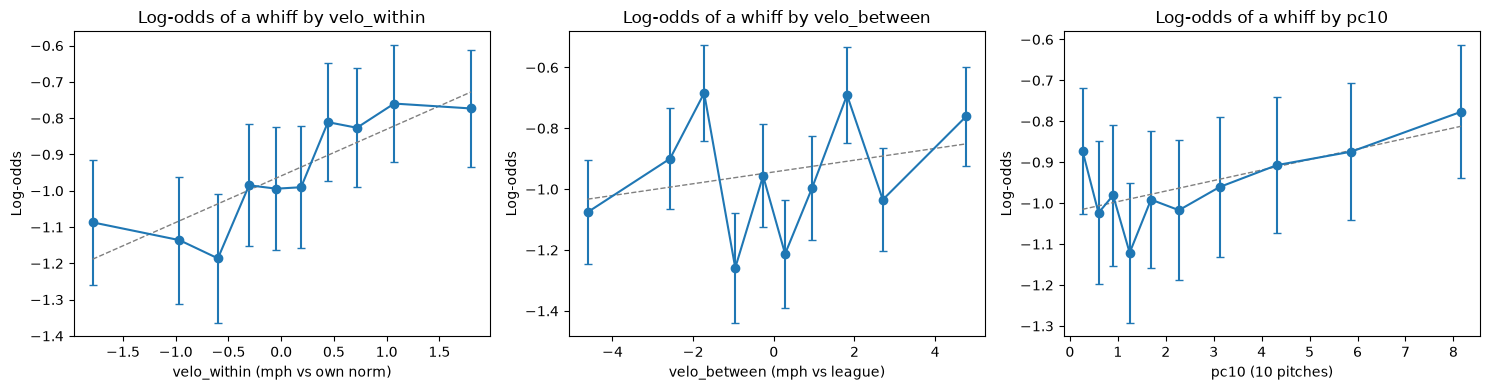

In [30]:
# Empirical log-odds of a whiff within quantile bins of a predictor
def binned_logodds(df_, col, q=10):
    b = pd.qcut(df_[col], q, duplicates='drop')
    g = df_.groupby(b, observed=True).agg(x=(col, 'mean'), n=('whiff', 'size'), p=('whiff', 'mean'))
    g['logit'] = np.log(g['p'] / (1 - g['p']))
    g['se'] = 1 / np.sqrt(g['n'] * g['p'] * (1 - g['p']))
    return g

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, (col, lab) in zip(ax, [('velo_within', 'velo_within (mph vs own norm)'),
                              ('velo_between', 'velo_between (mph vs league)'),
                              ('pc10', 'pc10 (10 pitches)')]):
    g = binned_logodds(model_df, col)
    a.errorbar(g['x'], g['logit'], yerr=1.96 * g['se'], marker='o', capsize=3)
    # Straight line through the bins, weighted by precision
    slope, icpt = np.polyfit(g['x'], g['logit'], 1, w=1 / g['se'])
    xs = np.linspace(g['x'].min(), g['x'].max(), 50)
    a.plot(xs, icpt + slope * xs, color='grey', ls='--', lw=1)
    a.set(title=f'Log-odds of a whiff by {col}', xlabel=lab, ylabel='Log-odds')
plt.tight_layout()
plt.show()

The reported model (Step 3) refit with a squared term added for each of the three numeric predictors, with the full output printed first. If a squared term is clearly nonzero, that predictor is curved.

In [31]:
# Step 3 plus a squared term for each numeric predictor, same pitcher-clustered errors
f_sq = f_m0_team + ' + I(velo_within**2) + I(velo_between**2) + I(pc10**2)'
res_sq = smf.logit(f_sq, data=model_df).fit(
    cov_type='cluster', cov_kwds={'groups': model_df['pitcher']}, disp=0)
print(res_sq.summary())

                           Logit Regression Results                           
Dep. Variable:                  whiff   No. Observations:                 6842
Model:                          Logit   Df Residuals:                     6786
Method:                           MLE   Df Model:                           55
Date:                Sun, 22 Nov 2026   Pseudo R-squ.:                  0.1589
Time:                        02:50:01   Log-Likelihood:                -3406.2
converged:                       True   LL-Null:                       -4049.6
Covariance Type:              cluster   LLR p-value:                5.064e-233
                                                            coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------------------------------------
Intercept                                                -1.6569      0.273     -6.063      0.000      -2.193      -1.121
C(

The three squared terms alone, with a Bonferroni cutoff across the three (0.05 / 3 = 0.0167).

In [32]:
sq_names = [n for n in res_sq.params.index if '** 2' in n and any(v in n for v in ['velo_within', 'velo_between', 'pc10'])]
sq = pd.DataFrame({'coef': res_sq.params[sq_names], 'p': res_sq.pvalues[sq_names]})
sq['Passes Bonferroni?'] = np.where(sq['p'] < 0.05 / len(sq_names), 'Yes', 'No')
print(sq.round(4))

                        coef       p Passes Bonferroni?
I(velo_within ** 2)   0.0203  0.1606                 No
I(velo_between ** 2)  0.0046  0.1718                 No
I(pc10 ** 2)          0.0025  0.6315                 No


Does the shape of these predictors matter for our results? Step 3 refit without `velo_between` (the jagged one), with the full output first.

In [33]:
# Step 3 without velo_between
f_nvb = f_m0_team.replace(' + velo_between', '')
res_nvb = smf.logit(f_nvb, data=model_df).fit(
    cov_type='cluster', cov_kwds={'groups': model_df['pitcher']}, disp=0)
print(res_nvb.summary())

                           Logit Regression Results                           
Dep. Variable:                  whiff   No. Observations:                 6842
Model:                          Logit   Df Residuals:                     6790
Method:                           MLE   Df Model:                           51
Date:                Sun, 22 Nov 2026   Pseudo R-squ.:                  0.1579
Time:                        02:50:01   Log-Likelihood:                -3410.3
converged:                       True   LL-Null:                       -4049.6
Covariance Type:              cluster   LLR p-value:                3.865e-234
                                                            coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------------------------------------
Intercept                                                -1.5996      0.282     -5.681      0.000      -2.151      -1.048
C(

The 15 reported coefficients under three specifications (Step 3, Step 3 with squared terms, Step 3 without `velo_between`), and which pass Bonferroni in each.

In [34]:
# Same 15 coefficients under each specification
t_sq, t_nvb = or_table(res_sq), or_table(res_nvb)
base = tabs['Step 3: + batting team']
sens = pd.DataFrame({
    'Step 3 OR': base.loc[rows, 'OR'], '+ squares OR': t_sq.loc[rows, 'OR'],
    'no velo_between OR': t_nvb.reindex(rows)['OR'],
    'Step 3 p': base.loc[rows, 'p'], '+ squares p': t_sq.loc[rows, 'p'],
    'no velo_between p': t_nvb.reindex(rows)['p']})
print(sens.round(4))

# Which pass Bonferroni under each specification
for n, t in [('Step 3', base), ('+ squares', t_sq), ('no velo_between', t_nvb)]:
    print(n, '->', [r for r in rows if r in t.index and t.loc[r, 'p'] < 0.05 / m])

                        Step 3 OR  + squares OR  no velo_between OR  Step 3 p  + squares p  no velo_between p
vs FF: CH                  1.3419        1.2961              1.3451    0.0548       0.0853             0.0477
vs FF: CU                  1.0942        1.0420              1.0926    0.5492       0.7816             0.5511
vs FF: FC                  0.8721        0.8578              0.8730    0.4350       0.3809             0.4323
vs FF: FS                  1.6849        1.5904              1.7026    0.0036       0.0145             0.0018
vs FF: KC                  1.2975        1.2456              1.3075    0.2774       0.3518             0.2672
vs FF: SI                  0.7018        0.7023              0.6989    0.0019       0.0019             0.0017
vs FF: SL                  1.1613        1.1436              1.1682    0.1721       0.2053             0.1627
vs FF: ST                  1.3508        1.3327              1.3546    0.0185       0.0261             0.0177
base: Firs

Correlation between the numeric predictors, including the squared location terms, the Jays flag and a starter indicator. Pairs above 0.7 in absolute value would be a concern.

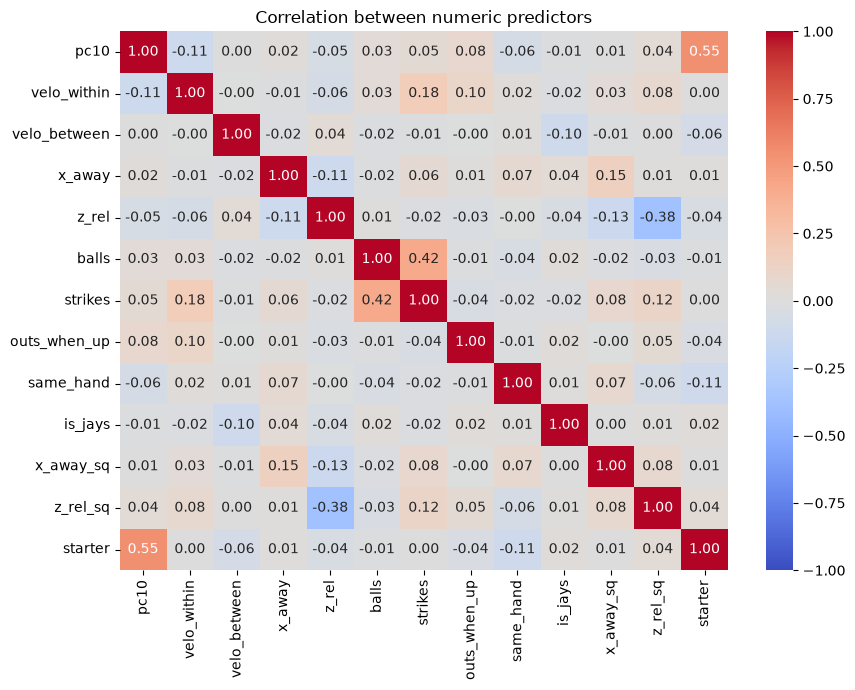

pc10         starter      0.55
balls        strikes      0.42
z_rel        z_rel_sq    -0.38
velo_within  strikes      0.18
x_away       x_away_sq    0.15
z_rel        x_away_sq   -0.13
dtype: float64
pairs over 0.7: {}


In [35]:
# Numeric predictors plus the squared location terms and two indicators
num = model_df[['pc10', 'velo_within', 'velo_between', 'x_away', 'z_rel', 'balls', 'strikes',
                'outs_when_up', 'same_hand', 'is_jays']].copy()
num['x_away_sq'] = model_df['x_away'] ** 2
num['z_rel_sq'] = model_df['z_rel'] ** 2
num['starter'] = (model_df['pitcher_role'] == 'starter').astype(int)
corr = num.corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation between numeric predictors')
plt.tight_layout()
plt.show()

# Largest pairs, and any over 0.7
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
print(pairs.reindex(pairs.abs().sort_values(ascending=False).index).head(6).round(2))
print('pairs over 0.7:', pairs[pairs.abs() > 0.7].round(2).to_dict())

Correlation only covers numeric predictors, so this checks the overlap that matters most (pitch type and location): if predictors were tangled, adding location would inflate the standard errors of the reported coefficients. Each column is the standard error divided by its Step 1 value, so values near 1 mean no inflation.

In [36]:
# Standard errors across the three steps, relative to Step 1
se = pd.DataFrame({n: r.bse for n, r in steps.items()})
se.index = (se.index.str.replace('C(pitch_type, Treatment("FF"))[T.', 'vs FF: ', regex=False)
                    .str.replace('C(base_group, Treatment("Empty"))[T.', 'base: ', regex=False)
                    .str.replace(']', '', regex=False))
ratio = se.loc[rows].div(se.loc[rows].iloc[:, 0], axis=0)
print(ratio.round(2))

                        Step 1: zones only  Step 2: + location  Step 3: + batting team
vs FF: CH                              1.0                0.92                    0.94
vs FF: CU                              1.0                1.07                    1.05
vs FF: FC                              1.0                1.03                    1.02
vs FF: FS                              1.0                0.96                    0.94
vs FF: KC                              1.0                1.03                    1.05
vs FF: SI                              1.0                1.10                    1.10
vs FF: SL                              1.0                1.03                    1.07
vs FF: ST                              1.0                1.05                    1.04
base: First only                       1.0                1.05                    1.05
base: Scoring position                 1.0                1.05                    1.04
pc10                                   1.0 

#### Summary
`velo_within` and pitch count are close to straight lines on the log-odds scale. `velo_between` looks jagged in the binned plot, but it is fixed for each pitcher and pitch type, so the plot's error bars are too narrow, and a squared term does not improve the model (p = 0.17 against a cutoff of 0.017). A squared term only detects smooth curvature, so the real check is whether the linear term matters: adding squared terms or dropping `velo_between` leaves most odds ratios within about 6%, and sinker and `velo_within` pass Bonferroni in every version. Scoring position and the splitter sit right at the Bonferroni cutoff and flip between passing and failing across these small changes, so we treat them as borderline. No two numeric predictors are strongly correlated (largest |r| is 0.55), and standard errors changed by at most about 10% as location and batting team were added.

## Lets try to get something more actionable for the Jays specifically, regarding the same question.

The M0 model compares pitch types and situations league-wide. Here we ask where the Blue Jays differ from what a league-average pitcher gets in the same situations. Criteria were set before running: a gap between observed and expected whiffs counts only if |z| is beyond the Bonferroni cutoff across the 9 pitch types (0.05 / 9, about 2.77); expected whiffs come from a model fit on non-Jays swings, shown with the Step 1, 2 and 3 controls, and we plot Step 3 (the reported model's controls); a coefficient is flagged as fragile if leaving out one pitcher moves its odds ratio by more than 10% or flips its Bonferroni pass/fail. The z-scores treat swings as independent, so they are optimistic.

#### Usage and effectiveness by pitch type (Jays vs everyone else)

How often each pitch type is thrown, how often it is swung at, and how often a swing misses, for the Jays and for all other pitchers.

In [37]:
t = non_bunt_pitches.groupby(['is_jays', 'pitch_type']).agg(
    pitches=('whiff', 'size'), swings=('swing', 'sum'), whiffs=('whiff', 'sum'))
t['usage']           = t['pitches'] / t.groupby(level=0)['pitches'].transform('sum')
t['swing_rate']      = t['swings'] / t['pitches']
t['whiff_per_swing'] = t['whiffs'] / t['swings']
t['whiff_per_pitch'] = t['whiffs'] / t['pitches']

side = t[['usage', 'swing_rate', 'whiff_per_swing', 'whiff_per_pitch']].unstack(0)
side.columns = [f"{m}_{'Jays' if j == 1 else 'Others'}" for m, j in side.columns]
side['jays_swings'] = t.loc[1, 'swings']
side['usage_diff']  = side['usage_Jays'] - side['usage_Others']
side['wps_diff']    = side['whiff_per_swing_Jays'] - side['whiff_per_swing_Others']
print(side.round(3))

            usage_Others  usage_Jays  swing_rate_Others  swing_rate_Jays  whiff_per_swing_Others  whiff_per_swing_Jays  whiff_per_pitch_Others  whiff_per_pitch_Jays  jays_swings  usage_diff  \
pitch_type                                                                                                                                                                                      
CH                 0.082       0.046              0.519            0.480                   0.381                 0.246                   0.198                 0.118           61      -0.036   
CU                 0.087       0.049              0.409            0.485                   0.366                 0.258                   0.150                 0.125           66      -0.038   
FC                 0.055       0.070              0.522            0.480                   0.211                 0.266                   0.110                 0.128           94       0.016   
FF                 0.328       0.33

#### Jays observed vs expected whiffs, all swings and two-strike swings

Observed whiffs against the number a league-average pitcher would get on the same swings, from a model fit on non-Jays swings with situation controls only (no velocity). `z` is the gap divided by its standard error and treats swings as independent.

In [38]:
league = model_df[model_df['is_jays'] == 0]
# Situation controls only, no velocity
fit_league = smf.logit(f_base, data=league).fit(disp=0)

def oe_table(jays_rows, fit=fit_league):
    j = jays_rows.copy()
    j['p_exp'] = fit.predict(j)
    out = j.groupby('pitch_type').agg(
        swings=('whiff', 'size'), obs=('whiff', 'sum'), exp=('p_exp', 'sum'),
        var=('p_exp', lambda p: (p * (1 - p)).sum()))
    out['obs_rate'] = out['obs'] / out['swings']
    out['exp_rate'] = out['exp'] / out['swings']
    out['O-E']      = out['obs'] - out['exp']
    out['z']        = out['O-E'] / np.sqrt(out['var'])
    return out.drop(columns='var')

jays_all = model_df[model_df['is_jays'] == 1]
# All counts
print(oe_table(jays_all).round(2))
# Two strikes (strikeout situations)
print(oe_table(jays_all[jays_all['strikes'] == 2]).round(2))

            swings  obs     exp  obs_rate  exp_rate    O-E     z
pitch_type                                                      
CH              61   15   20.66      0.25      0.34  -5.66 -1.61
CU              66   17   24.20      0.26      0.37  -7.20 -1.97
FC              94   25   17.98      0.27      0.19   7.02  1.89
FF             436   74  102.95      0.17      0.24 -28.95 -3.35
FS             185   93   73.04      0.50      0.39  19.96  3.17
KC              80   34   32.56      0.42      0.41   1.44  0.35
SI              61   11    8.90      0.18      0.15   2.10  0.79
SL             256  105   85.55      0.41      0.33  19.45  2.75
ST              57   23   19.93      0.40      0.35   3.07  0.90
            swings  obs    exp  obs_rate  exp_rate    O-E     z
pitch_type                                                     
CH              17    5   5.54      0.29      0.33  -0.54 -0.29
CU              27    9  10.49      0.33      0.39  -1.49 -0.64
FC              33    9   5.0

The same comparison with expected whiffs from a league model that adds exact location (Step 2) and then batting team (Step 3), the same three sets as M0. A pitch type counts as different from expected only if |z| is beyond the Bonferroni cutoff across the 9 pitch types.

In [39]:
# Same controls as M0 Steps 1-3, fit on non-Jays swings, no velocity
loc_terms = ' + x_away + z_rel + I(x_away**2) + I(z_rel**2) + x_away:z_rel'
exp_forms = {'Step 1: zones only': f_base,
             'Step 2: + location': f_base + loc_terms,
             'Step 3: + batting team': f_base + loc_terms + ' + C(bat_team)'}
# Step 1 is the league model already fit above
exp_fits = {'Step 1: zones only': fit_league}
for n_, f_ in list(exp_forms.items())[1:]:
    exp_fits[n_] = smf.logit(f_, data=league).fit(disp=0)

# Two-sided Bonferroni cutoff across the pitch types
n_types = jays_all['pitch_type'].nunique()
cut_z = stats.norm.isf(0.05 / n_types / 2)
print(f'{n_types} pitch types, Bonferroni cutoff |z| > {cut_z:.2f}')

def oe_compare(rows_):
    tabs_ = {n_: oe_table(rows_, f_) for n_, f_ in exp_fits.items()}
    first = next(iter(tabs_.values()))
    cmp_ = pd.DataFrame({'swings': first['swings'], 'obs_rate': first['obs_rate']})
    for n_, t_ in tabs_.items():
        k = n_.split(':')[0]
        cmp_[f'exp {k}'] = t_['exp_rate']
        cmp_[f'z {k}'] = t_['z']
    print(cmp_.round(2))
    for n_, t_ in tabs_.items():
        print(n_, '-> beyond cutoff:', [p_ for p_ in t_.index if abs(t_.loc[p_, 'z']) > cut_z])

print('All swings')
oe_compare(jays_all)
print('Two-strike swings')
oe_compare(jays_all[jays_all['strikes'] == 2])

9 pitch types, Bonferroni cutoff |z| > 2.77
All swings
            swings  obs_rate  exp Step 1  z Step 1  exp Step 2  z Step 2  exp Step 3  z Step 3
pitch_type                                                                                    
CH              61      0.25        0.34     -1.61        0.33     -1.41        0.34     -1.69
CU              66      0.26        0.37     -1.97        0.31     -0.94        0.33     -1.34
FC              94      0.27        0.19      1.89        0.18      2.17        0.20      1.67
FF             436      0.17        0.24     -3.35        0.23     -2.94        0.25     -3.83
FS             185      0.50        0.39      3.17        0.41      2.93        0.44      1.98
KC              80      0.42        0.41      0.35        0.43     -0.01        0.44     -0.41
SI              61      0.18        0.15      0.79        0.16      0.44        0.18      0.07
SL             256      0.41        0.33      2.75        0.34      2.57        0.37      

Which batting teams the Jays' pitchers faced compared with the teams behind the benchmark swings, and the average batting-team effect on whiff log-odds from the Step 3 fit (BOS is the baseline). This checks whether the opponent mix explains why expected whiffs change at Step 3.

In [40]:
mix = pd.crosstab(model_df['bat_team'], model_df['is_jays'], normalize='columns')
mix.columns = ['Others', 'Jays']
print(mix.round(3))

# Average batting-team effect on whiff log-odds, from the Step 3 fit (BOS is the baseline, so 0)
bt_eff = res_team.params.filter(like='bat_team')
bt_eff.index = bt_eff.index.str.extract(r'\[T\.(\w+)\]')[0]
bt_eff = bt_eff.reindex(mix.index).fillna(0)
print(mix.mul(bt_eff, axis=0).sum().round(3))

          Others   Jays
bat_team               
BOS        0.035  0.000
CHC        0.101  0.000
CIN        0.027  0.000
CLE        0.036  0.000
DET        0.115  0.000
LAD        0.129  0.421
MIL        0.102  0.000
NYY        0.038  0.213
PHI        0.054  0.000
SD         0.036  0.000
SEA        0.074  0.366
TOR        0.253  0.000
Others   -0.259
Jays     -0.126
dtype: float64


For the three pitch types the old write-up built on (fastball, splitter, slider): each Jays pitcher's whiffs against the Step 3 expectation, and the total gap and z-score with that pitcher left out. This shows whether one pitcher drives a pitch type's result.

In [41]:
# Step 3 expectation, the controls of the reported model
fit_exp = exp_fits['Step 3: + batting team']

def by_pitcher(pt, fit=fit_exp):
    j = jays_all[jays_all['pitch_type'] == pt].copy()
    j['p_exp'] = fit.predict(j)
    g = j.groupby('player_name').agg(
        swings=('whiff', 'size'), whiffs=('whiff', 'sum'), exp=('p_exp', 'sum'),
        var=('p_exp', lambda p: (p * (1 - p)).sum()))
    g['whiff_rate'] = g['whiffs'] / g['swings']
    g['exp_rate']   = g['exp'] / g['swings']
    g['O-E']        = g['whiffs'] - g['exp']
    # Total gap with each pitcher left out
    tot = g[['whiffs', 'exp', 'var']].sum()
    g['O-E without'] = (tot['whiffs'] - g['whiffs']) - (tot['exp'] - g['exp'])
    g['z without']   = (g['O-E without'] / np.sqrt(tot['var'] - g['var'])).replace([np.inf, -np.inf], np.nan)
    return g.drop(columns=['exp', 'var']).sort_values('swings', ascending=False)

for pt in ['FF', 'FS', 'SL']:
    print(pt)
    print(by_pitcher(pt).round(2))

FF
                       swings  whiffs  whiff_rate  exp_rate    O-E  O-E without  z without
player_name                                                                               
Gausman, Kevin             99      10        0.10      0.24 -13.83       -19.39      -2.54
Yesavage, Trey             64      12        0.19      0.27  -5.27       -27.95      -3.50
Scherzer, Max              49       9        0.18      0.28  -4.92       -28.30      -3.48
Varland, Louis             48       7        0.15      0.21  -3.28       -29.94      -3.65
Domínguez, Seranthony      45      13        0.29      0.23   2.79       -36.00      -4.37
Lauer, Eric                36       3        0.08      0.21  -4.66       -28.56      -3.42
Hoffman, Jeff              34       8        0.24      0.25  -0.59       -32.63      -3.92
Bieber, Shane              33       6        0.18      0.27  -2.97       -30.25      -3.63
Bassitt, Chris             15       3        0.20      0.21  -0.20       -33.02      -3

The Step 3 model refit once for each pitcher with that pitcher's swings removed (this can take a minute or two). The flag was set in advance: an odds ratio that moves more than 10% or flips its Bonferroni pass/fail. The Jays pitch-count slope is not one of the 15 tests, so its pass/fail uses p < 0.05.

In [42]:
# Key coefficients, plus the Jays pitch-count slope (pc10 + pc10:is_jays) from the clustered covariance
key = ['vs FF: SI', 'vs FF: FS', 'base: Scoring position', 'velo_within', 'is_jays', 'pc10:is_jays', 'Jays slope']

def key_row(res):
    t_ = or_table(res)
    out = {k: (t_.loc[k, 'OR'], t_.loc[k, 'p']) if k in t_.index else (np.nan, np.nan) for k in key[:-1]}
    b, V = res.params, res.cov_params()
    s = b['pc10'] + b['pc10:is_jays']
    v = V.loc['pc10', 'pc10'] + V.loc['pc10:is_jays', 'pc10:is_jays'] + 2 * V.loc['pc10', 'pc10:is_jays']
    out['Jays slope'] = (np.exp(s), 2 * stats.norm.sf(abs(s / np.sqrt(v))))
    return out

full_row = key_row(res_team)

# Refit Step 3 without each pitcher in turn
lopo = {}
for pid in model_df['pitcher'].unique():
    d = model_df[model_df['pitcher'] != pid]
    r = smf.logit(f_m0_team, data=d).fit(cov_type='cluster', cov_kwds={'groups': d['pitcher']}, disp=0)
    lopo[pid] = {f'{k} {c}': v for k, vv in key_row(r).items() for c, v in zip(['OR', 'p'], vv)}
lopo = pd.DataFrame(lopo).T

info = model_df.drop_duplicates('pitcher').set_index('pitcher')
lopo['pitcher'] = info['player_name']
lopo['is_jays'] = info['is_jays']
lopo['swings'] = model_df.groupby('pitcher').size()

# Summary per coefficient
summ, flip_lists = [], {}
for k in key:
    orv, pv = lopo[f'{k} OR'], lopo[f'{k} p']
    full_or, full_p = full_row[k]
    cut = 0.05 / m if k != 'Jays slope' else 0.05
    pct = (orv / full_or - 1) * 100
    worst = pct.abs().idxmax()
    flips = (pv < cut) != (full_p < cut)
    summ.append({'coef': k, 'full OR': full_or, 'min OR': orv.min(), 'max OR': orv.max(),
                 'largest change %': pct[worst], 'dropped': lopo.loc[worst, 'pitcher'],
                 'drops >10%': int((pct.abs() > 10).sum()),
                 'passes in full model': bool(full_p < cut), 'drops that flip': int(flips.sum())})
    flip_lists[k] = lopo.loc[flips, 'pitcher'].tolist()
summ = pd.DataFrame(summ).set_index('coef')
print(f'{len(lopo)} pitchers dropped one at a time (Step 3 refit each time)')
print(summ.round(3))
for k, v in flip_lists.items():
    print(k, 'flips when dropping:', v if len(v) <= 10 else f'{len(v)} different pitchers, so no single one drives it')

# The five drops that move each of these odds ratios the most
for k in ['vs FF: FS', 'vs FF: SI']:
    pct = (lopo[f'{k} OR'] / full_row[k][0] - 1) * 100
    top = pct.abs().sort_values(ascending=False).head(5).index
    print(k)
    print(pd.DataFrame({'pitcher': lopo.loc[top, 'pitcher'], 'swings': lopo.loc[top, 'swings'],
                        'OR': lopo.loc[top, f'{k} OR'], 'p': lopo.loc[top, f'{k} p'],
                        '% change': pct[top]}).round(4))

143 pitchers dropped one at a time (Step 3 refit each time)
                        full OR  min OR  max OR  largest change %          dropped  drops >10%  passes in full model  drops that flip
coef                                                                                                                                 
vs FF: SI                 0.702   0.677   0.741             5.594     Ashby, Aaron           0                  True                5
vs FF: FS                 1.685   1.512   1.798           -10.269   Gausman, Kevin           1                 False               28
base: Scoring position    0.808   0.793   0.821            -1.875    Hoffman, Jeff           0                  True               86
velo_within               1.122   1.107   1.136            -1.345  Peralta, Freddy           0                  True                0
is_jays                   1.072   1.017   1.134             5.834    Bieber, Shane           0                 False                0
pc

#### Plots

Observed minus expected whiff rate for each Jays pitch type, using Step 3 expected whiffs. A dot is filled only if |z| passes Bonferroni across the 9 pitch types. The odds-ratio plot and Jays pitch-count slope from this original cell are already in Section 3, along with the colours and `clean_axes`.

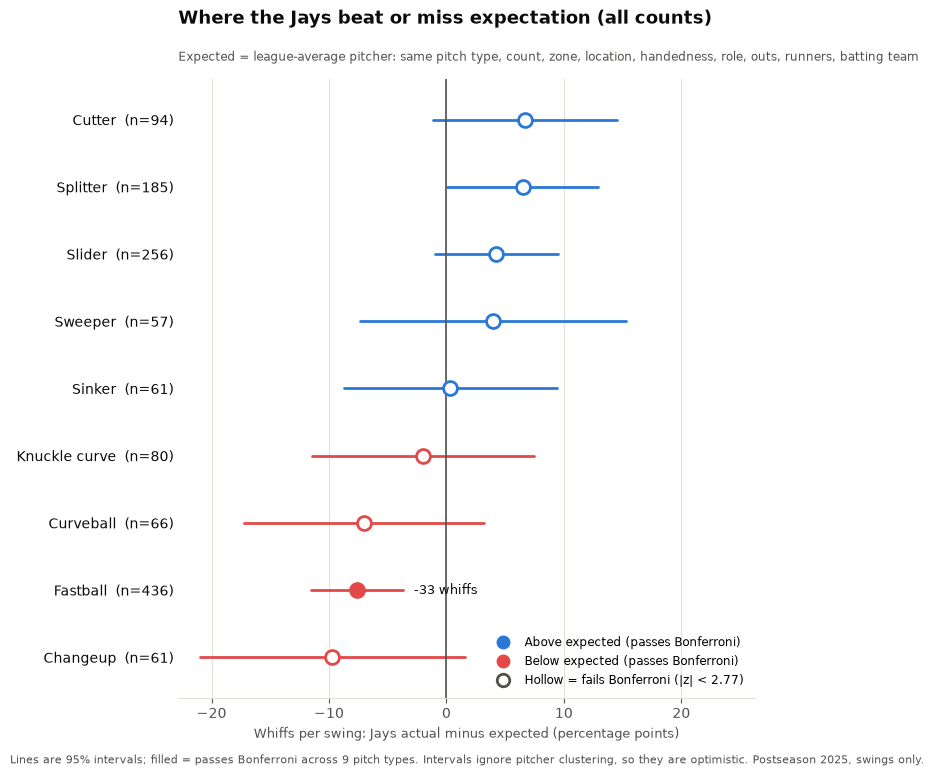

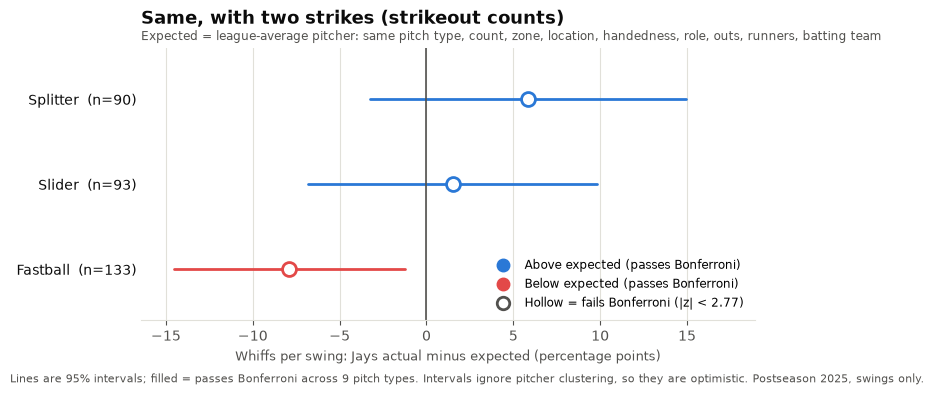

In [43]:
def oe_plot(rows, title, min_n=30, fit=fit_exp,
            sub='Expected = league-average pitcher: same pitch type, count, zone, location, '
                'handedness, role, outs, runners, batting team'):
    j = rows.copy(); j['p_exp'] = fit.predict(j)
    g = j.groupby('pitch_type').agg(n=('whiff','size'), obs=('whiff','sum'), exp=('p_exp','sum'),
                                    var=('p_exp', lambda p: (p*(1-p)).sum()))
    g['diff_pp'] = (g['obs']-g['exp'])/g['n']*100
    g['half'] = 1.96*np.sqrt(g['var'])/g['n']*100
    g['z'] = (g['obs']-g['exp'])/np.sqrt(g['var'])
    g = g[g['n'] >= min_n].sort_values('diff_pp')
    fig, ax = plt.subplots(figsize=(8.5, 0.62*len(g)+2.0))
    for yi, (pt, r) in enumerate(g.iterrows()):
        sig = abs(r.z) > cut_z
        c = BLUE if r.diff_pp > 0 else RED
        ax.plot([r.diff_pp-r.half, r.diff_pp+r.half], [yi, yi], color=c, lw=2, solid_capstyle='round')
        ax.plot(r.diff_pp, yi, 'o', ms=10, mfc=c if sig else 'white', mec=c, mew=2, zorder=3)
        if sig:
            ax.annotate(f"{r.obs-r.exp:+.0f} whiffs", (r.diff_pp+r.half, yi), xytext=(8,0),
                        textcoords='offset points', va='center', fontsize=9, color=INK)
    ax.axvline(0, color=MUTED, lw=1.2)
    ax.set_yticks(range(len(g)))
    ax.set_yticklabels([f"{PT.get(p,p)}  (n={int(n)})" for p, n in zip(g.index, g['n'])], fontsize=10)
    ax.set_ylim(-0.6, len(g)-0.4)
    ax.set_xlabel('Whiffs per swing: Jays actual minus expected (percentage points)', color=MUTED, fontsize=9)
    clean_axes(ax)
    lo, hi = ax.get_xlim(); mx = max(abs(lo), abs(hi)); ax.set_xlim(-mx, mx*1.15)
    ax.text(0, 1.09, title, transform=ax.transAxes, fontsize=13, fontweight='bold', color=INK)
    ax.text(0, 1.03, sub, transform=ax.transAxes, fontsize=8.5, color=MUTED)
    ax.legend(handles=[
        Line2D([],[],marker='o',ls='',ms=9,mfc=BLUE,mec=BLUE,label='Above expected (passes Bonferroni)'),
        Line2D([],[],marker='o',ls='',ms=9,mfc=RED,mec=RED,label='Below expected (passes Bonferroni)'),
        Line2D([],[],marker='o',ls='',ms=9,mfc='white',mec=MUTED,mew=2,label=f'Hollow = fails Bonferroni (|z| < {cut_z:.2f})')],
        loc='lower right', frameon=False, fontsize=8.5)
    fig.text(0.01, -0.01, f'Lines are 95% intervals; filled = passes Bonferroni across {n_types} pitch types. '
             'Intervals ignore pitcher clustering, so they are optimistic. Postseason 2025, swings only.',
             fontsize=8, color=MUTED)
    plt.tight_layout(); return fig

jays = model_df[model_df['is_jays'] == 1]
fig_a1 = oe_plot(jays, 'Where the Jays beat or miss expectation (all counts)')
fig_a2 = oe_plot(jays[jays['strikes'] == 2], 'Same, with two strikes (strikeout counts)', min_n=40)
for f_, name in [(fig_a1, 'fig_oe_all'), (fig_a2, 'fig_oe_two_strike')]:
    f_.savefig(f'{name}.png', dpi=200, bbox_inches='tight')

#### Summary
Against what a league-average pitcher gets in the same situations, the Jays fastball is the result that holds up best: about 33 fewer whiffs than expected on 436 swings, beyond the Bonferroni cutoff under all three sets of controls and below expectation for 10 of the 12 Jays pitchers who threw one, although Gausman accounts for about 14 of the 33 and without him the z-score is −2.5, just short of the cutoff. The splitter and slider look strong against the simple benchmark but not after adjusting for exact location and the opponents faced: the Jays only faced LAD, SEA and NYY, while a quarter of the benchmark swings are against Toronto's own hitters, who have the lowest batting-team whiff coefficient. The splitter's remaining excess is mostly Yesavage (about 10 of 12 whiffs) and the slider's is mostly Hoffman. Leaving out one pitcher at a time, the `velo_within` odds ratio never moves more than about 1.5% and sinker keeps its Bonferroni pass in 138 of 143 refits, while scoring position and the splitter flip across many refits because their p-values sit at the cutoff, even though scoring position's odds ratio stays between 0.79 and 0.82.

## What the Blue Jays can do (postseason 2025, whiff per swing)

Findings are grouped by how well they held up. All are associations from one postseason, not causes.

**Supported**
- **The fastball is the weak spot (best supported, but the z-scores ignore pitcher clustering).** Jays fastballs get 17% whiffs per swing vs 24% for the league, about 33 fewer whiffs than a league-average fastball would get in the same count, zone, location and against the same opponents. The gap passes Bonferroni at all three control levels, and 10 of the 12 Jays pitchers who threw one are below expectation. One caveat: Gausman accounts for about 14 of the 33, and without him the gap falls just short of the cutoff. Worth reviewing fastball quality and location. Whiff alone doesn't capture setup value or contact quality.
- **Velocity against a pitcher's own norm.** Each mph above a pitcher's own norm goes with about 12% higher whiff odds (OR 1.12, 95% CI 1.05–1.20), so a pitcher 1 mph below his norm goes with about 11% lower. It passes Bonferroni in every model and moves less than 2% when any one pitcher is left out. Velocity against each pitcher's own norm is worth tracking.
- **The sinker is a contact pitch.** Sinkers get fewer whiffs than fastballs league-wide (OR 0.70), and Jays sinkers match that expectation. Use it for ground balls, not strikeouts.

**Suggestive (failed at least one check)**
- **Splitter.** Raw numbers favour it: 50% whiffs per swing vs 37% for the league, thrown 14% of the time vs 6%. The gap passes Bonferroni with simple controls but not once exact location and batting team are added, and about 10 of its 12 extra whiffs come from Yesavage. Its M0 odds ratio (1.69) narrowly misses Bonferroni and falls to about 1.5 if either Gausman or Yesavage is left out. Yesavage's splitter may be worth a closer look, but "the Jays' best pitch" is not established.
- **Runners in scoring position.** Whiff odds are about 19% lower (OR 0.81), a league-wide pattern rather than a Jays one. The p-value sits right at the Bonferroni cutoff and flips in 86 of 143 leave-one-out refits, but the odds ratio stays between 0.79 and 0.82. Runner on first only is similar (about 17% lower) but does not pass. Planning for contact outs with runners on is reasonable, but weakly supported.
- **Pitch count.** League-wide, whiff odds do not change with pitch count. For the Jays the slope is 0.95 per 10 pitches (p ≈ 0.035, not Bonferroni-corrected, flipping in 9 of 143 refits), and velocity falls about 0.3 mph over an outing. Treat a Jays-specific decline as a flag only.

**Not supported**
- **Slider as a strikeout pitch.** 41% vs 31% in the raw numbers, but not beyond the cutoff under any control set, and about 6.5 of its 11 extra whiffs come from Hoffman.
- **Two-strike pitch choice.** No pitch type is beyond the cutoff in any two-strike table (fastball lowest, z about −2.3), so there is no basis yet for shifting two-strike usage between pitch types.
- **Changeup and curve** are below the league in raw whiff rate (about 25% vs 37–38%) but small samples (about 60 swings each) and not beyond the cutoff: flags only.

**Limits:** one postseason; the Jays faced only LAD, SEA and NYY; 15 Jays pitchers, with several pitch types concentrated in a few of them; z-scores ignore clustering by pitcher; three control sets and two count groups were examined, and Bonferroni corrects only within one table; whiff is one dimension of effectiveness.

## Conclusions, limitations and next steps

### What we can conclude
The question was which features of a pitch are associated with a whiff per swing, and whether the Blue Jays' pitchers differ from what other pitchers get in the same situations. All findings are associations from one postseason.

- **Robust:** sinkers draw fewer whiffs than four-seam fastballs (OR 0.70), and a pitch faster than the pitcher's own norm draws more (OR 1.12 per mph). Both pass Bonferroni at every step and in the sensitivity and leave-one-pitcher-out checks.
- **Best-supported Jays result:** Jays fastballs get about 33 fewer whiffs than expected (17% vs 24% per swing in the raw numbers), beyond the cutoff under all three sets of controls. The z-scores ignore pitcher clustering, and Gausman accounts for about 14 of the 33.
- **Borderline:** runners in scoring position (OR 0.81) and the splitter (OR 1.69) sit at the Bonferroni cutoff and flip under small changes.
- **Jays vs the league overall:** no clear difference (OR 1.07, 95% CI 0.82 to 1.40).
- **What shrank under scrutiny is itself a result.** The splitter's raw advantage (50% vs 37% whiffs per swing, about 13 points) falls to about 6.5 points above expectation once exact location and opponents are controlled, and most of that is one pitcher (Yesavage). The curveball, knuckle-curve and slider advantages that looked significant before location was controlled shrank toward 1. Raw comparisons would have overstated all of these.

### Limitations
- **Data size.** One postseason: 6,842 swings and 15 Jays pitchers. With a Bonferroni correction across 15 coefficients only large effects pass, so "borderline" and "not supported" mean undecided, not absent.
- **Association, not cause.** Location and opponent controls reduce confounding but cannot remove it. Pitch sequencing, batter quality and game situation are not modelled.
- **Whiff is one outcome.** It misses contact quality, setup value and run value.
- **Clustering and concentration.** M0 clusters standard errors by pitcher, but the observed-vs-expected z-scores do not. Several results come from a few pitchers: Gausman and Yesavage threw 152 of the 185 Jays splitter swings.
- **Model choice.** AIC prefers Step 3 and BIC prefers Step 2, and the likelihood-ratio tests are approximate under clustering. The `velo_between` plot is jagged and the squared-term test only detects smooth curves, so we checked the results with and without it.
- **M1.** Variational Bayes intervals are too narrow, so M1 is a stability check, not a test. Random intercepts alone cannot capture pitcher-specific pitch effects (reasoning, not tested), and a batter random effect was not run.
- **Multiple looks.** Observed-vs-expected was examined under three sets of controls and two count groups, and Bonferroni corrects only within one table.
- **Opponents.** The Jays faced only LAD, SEA and NYY, while a quarter of the benchmark swings are against Toronto's own hitters. That this explains why the splitter and slider results shrink is reasoning supported by the batting-team coefficients, not a direct test.
- **Not predictive.** Calibration was not assessed, so the model is not meant for predicting individual swings.

### Next steps
- **Baseball context.** A whiff is worth different amounts in different situations: a strikeout with a runner on third matters more than one with the bases empty, and weak contact can be as good as a whiff in others. Narrow situations like these have too few swings in one postseason, so studying them needs more data.
- **Outcomes beyond whiff.** Contact quality and run value (for example the change in run expectancy) would show effectiveness that whiff alone misses.
- **Replication.** Check whether the fastball deficit and the borderline results hold on other data, such as regular-season pitches.
- **Richer models.** Pitcher-specific pitch effects (random slopes) and a batter random effect, with enough data to estimate them.
- **Clustering in the Jays comparison.** A version of the observed-vs-expected test that accounts for pitcher clustering.